# STEP 11. 2026Q2 forecast

This is finally the last step of the pipeline. **Features from quarter 20261 are used to forecast 20262.**

| | Feature quarter | Target quarter | Label |
|---|---|---|---|
| Training | 20231 ~ 20253 | 20232 ~ 20254 | available |
| Validation | 20254 | 20261 | available |
| **Forecast** | **20261** | **20262** | **none <- what we are building now** |

## Three things are forecast

What STEP 10 taught us: **net decline is the difference between openings and closures**, so one number is not enough. We report all three side by side.

| Forecast | Model | Meaning |
|---|---|---|
| **Net-decline transition probability** | STEP 8 boosting | Probability that the store count turns into a net decline next quarter |
| **Closure rate** | Negative binomial (STEP 10 approach) | Closures next quarter per 100 stores |
| **Opening rate** | Negative binomial | Openings next quarter per 100 stores |

> ⚠️ **"Net-decline probability" and "closure rate" are different things.** The former is dragged along by size (STEP 9-2), the latter is not. The two rankings can disagree, and in fact they do. We check this in 11-4.

## Scope

We forecast **neighborhood commercial areas only**. H2 and sub-question 2 targeted neighborhood commercial areas, and the model was trained on that sample.

We do not build a district x service category table: another part of the project owns the core question, and STEP 8 showed that this unit **cannot be validated on a single quarter** (split-half reliability +0.035). However, **cell-level forecasts are saved**, so they can be reused if needed.

In [1]:
import sys, os
from pathlib import Path

# Find the project root wherever the notebook is opened and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# If the kernel is not restarted after editing config.py, Python keeps the old cached module.
import importlib
if "config" in sys.modules:
    importlib.reload(sys.modules["config"])

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

Project root: seoul-closure-risk


In [2]:
import pickle, warnings
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
from config import (SVC_ORDER, dummies, PROC, FIG, TARGET_TYPE, TRAIN_QUARTERS, VALID_Q, SCORE_Q, SEED,
                    build_features, design_matrix, set_plot_style)
set_plot_style()
warnings.filterwarnings("ignore")
OUT = FIG.parent
B_BOOT = 500

# -- Load the originals (keep _raw) ───────────────────────
panel_raw  = pd.read_pickle(PROC / "03_panel.pkl")
score_raw  = pd.read_pickle(PROC / "03_score.pkl")
merged_raw = pd.read_pickle(PROC / "02_merged.pkl")
with open(PROC / "08_model.pkl", "rb") as f:
    bundle = pickle.load(f)

print(f"Training/validation panel {panel_raw.shape}")
print(f"Scoring frame   {score_raw.shape}  quarter {score_raw['quarter_code'].unique()}")
print(f"STEP 8 model   {bundle['model_name']} | validation AUC {bundle['valid_metrics']['AUC']:.3f}")

Training/validation panel (67475, 34)
Scoring frame   (5428, 32)  quarter [20261]
STEP 8 model   E boosting | validation AUC 0.669


## 11-1. Prepare the working copies

Same principle as STEP 1: first cut down to the needed range, then `.copy()`.

In [3]:
# For training (neighborhood areas, training quarters) + next-quarter opening and closure counts
nx = merged_raw.copy()
nx["quarter_idx"] = nx["quarter_code"].map(lambda x: (x // 10) * 4 + (x % 10 - 1))
nx = nx[["area_code", "service_code", "quarter_idx", "opening_count", "closure_count"]] \
       .rename(columns={"opening_count": "opening_n", "closure_count": "closure_n"})

def attach_next(frame):
    f = frame.assign(nxt=frame["quarter_idx"] + 1)
    return f.merge(nx, left_on=["area_code", "service_code", "nxt"],
                   right_on=["area_code", "service_code", "quarter_idx"],
                   how="left", suffixes=("", "_r"), validate="many_to_one")

train = build_features(panel_raw[(panel_raw["area_type"] == TARGET_TYPE) &
                                 (panel_raw["quarter_code"].isin(TRAIN_QUARTERS))].copy())
train = attach_next(train)

valid = build_features(panel_raw[(panel_raw["area_type"] == TARGET_TYPE) &
                                 (panel_raw["quarter_code"] == VALID_Q)].copy())
valid = attach_next(valid)

score = build_features(score_raw[score_raw["area_type"] == TARGET_TYPE].copy())

print(f"Training {len(train):,} rows | validation {len(valid):,} rows | scoring {len(score):,} rows")
assert score["quarter_code"].unique().tolist() == [SCORE_Q]
assert VALID_Q not in train["quarter_code"].values, "Leakage: the validation quarter is in the training data"
print("✅ Leakage check passed")

Training 31,875 rows | validation 2,772 rows | scoring 2,737 rows
✅ Leakage check passed


## 11-2. Net-decline transition probability: STEP 8 model

We load the saved model as it is and score with it. Features are built with `config.design_matrix`, so this is **exactly the same way as in training**.

In [4]:
def p_net(frame):
    X = design_matrix(frame, bundle["columns"])
    if bundle["needs_impute"]:
        X = X.fillna(bundle["median"])
    return bundle["model"].predict_proba(X)[:, 1]

score["p_net_decline"] = p_net(score)
valid["p_net_decline"] = p_net(valid)
print(f"Predicted probability distribution  mean {score['p_net_decline'].mean():.3f} | "
      f"5~95% {score['p_net_decline'].quantile(.05):.3f}~{score['p_net_decline'].quantile(.95):.3f}")

Predicted probability distribution  mean 0.231 | 5~95% 0.114~0.390


## 11-3. Opening rate and closure rate: negative binomial model

This follows the STEP 10 approach. Next-quarter opening and closure **counts** are modeled separately, and the offset `log(store count)` yields the **rates**.

**No quarter dummies are included.** The forecast target 20261 is a quarter that is not in the training data, so a dummy cannot be created for it (same principle as STEP 8).

In [5]:
FEA = ["log_store_count", "log_foot_traffic", "log_area_size", "log_attracting_facilities",
       "food_service_share", "franchise_share"]

def design_count(f, cols=None):
    X = pd.concat([f[FEA],
                   dummies(f["service_name"], prefix="svc"),
                   dummies(f["district"], prefix="gu")], axis=1).astype(float)
    X = sm.add_constant(X, has_constant="add")
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)

Xt = design_count(train)
CCOLS = list(Xt.columns)
fitted = {}
for yv, nm in [("opening_n", "opening"), ("closure_n", "closure")]:
    fitted[nm] = sm.GLM(train[yv], Xt,
                        family=sm.families.NegativeBinomial(alpha=1.0),
                        offset=np.log(train["store_count"])).fit()

def predict_rates(frame):
    X = design_count(frame, CCOLS)
    off = np.log(frame["store_count"]).to_numpy()
    out = {}
    for nm, m in fitted.items():
        cnt = m.predict(X, offset=off)
        out[f"pred_{nm}_count"] = cnt
        out[f"pred_{nm}_rate"] = cnt / frame["store_count"].to_numpy() * 100   # per 100 stores
    return pd.DataFrame(out, index=frame.index)

score = score.join(predict_rates(score))
valid = valid.join(predict_rates(valid))
print(f"Fitted on {len(train):,} training rows | {len(CCOLS)} features")
print(f"Scoring done: mean predicted closure rate {score['pred_closure_rate'].mean():.2f}% "
      f"({score['pred_closure_rate'].mean():.1f} closures per 100 stores)")

Fitted on 31,875 training rows | 42 features
Scoring done: mean predicted closure rate 4.50% (4.5 closures per 100 stores)


## 11-4. 2026Q2 forecast results ★

We aggregate by service category. The point of this table is to **put the net-decline probability ranking and the closure-rate ranking side by side**.

In [6]:
def by_svc(f):
    return (f.groupby("service_name")
            .agg(n_cells=("p_net_decline", "size"), mean_stores=("store_count", "mean"),
                 net_decline_prob=("p_net_decline", "mean"),
                 pred_closure_rate=("pred_closure_rate", "mean"),
                 pred_opening_rate=("pred_opening_rate", "mean"))
            .assign(net_change_rate=lambda d: d["pred_opening_rate"] - d["pred_closure_rate"]))

pred = by_svc(score)
pred["net_decline_rank"] = pred["net_decline_prob"].rank(ascending=False, method="min").astype(int)
pred["closure_rate_rank"] = pred["pred_closure_rate"].rank(ascending=False, method="min").astype(int)
display(pred.sort_values("pred_closure_rate", ascending=False).round(2))

rho = spearmanr(pred["net_decline_prob"], pred["pred_closure_rate"]).statistic
print(f"Correlation of the two rankings: {rho:+.3f}")
print(f"※ Units: closure and opening rates are 'next-quarter counts per 100 stores'; net-decline probability is 'the probability that the cell turns into a net decline'")

,n_cells,mean_stores,net_decline_prob,pred_closure_rate,pred_opening_rate,net_change_rate,net_decline_rank,closure_rate_rank
service_name,,,,,,,,
Fast-food restaurants,104,6.82,0.20,5.55,3.76,-1.80,8,1
Fried-chicken shops,149,6.50,0.20,5.20,3.10,-2.10,7,2
Korean snack-food restaurants,276,8.10,0.21,4.96,3.92,-1.05,5,3
Chinese restaurants,94,9.89,0.21,4.91,4.05,-0.86,6,4
Coffee and beverages,616,12.42,0.24,4.88,4.30,-0.58,2,5
Japanese restaurants,74,8.36,0.20,4.59,3.73,-0.85,9,6
Western restaurants,116,11.60,0.24,4.45,3.84,-0.61,3,7
Bakeries,133,7.47,0.20,4.43,3.37,-1.06,10,8
Beer and casual pubs,350,11.24,0.23,4.02,2.91,-1.11,4,9


Correlation of the two rankings: -0.370
※ Units: closure and opening rates are 'next-quarter counts per 100 stores'; net-decline probability is 'the probability that the cell turns into a net decline'


### The two indicators point in opposite directions

Same data, same quarter, same service category, yet **the ranking flips.** This is not an error: **the two indicators measure different things.**

- **Net-decline probability**: dragged along by size (STEP 9-2). A cell with many stores has a high chance of something happening, so it is easily flagged as a net decline
- **Closure rate**: divided by the number of stores, so the size effect is removed

**Use the closure rate for policy decisions.** The net-decline probability only answers "will this cell shrink?", not "are the stores here at risk?".

In [7]:
cmp = pred[["mean_stores", "net_decline_prob", "net_decline_rank", "pred_closure_rate", "closure_rate_rank"]].copy()
cmp["rank_diff"] = cmp["net_decline_rank"] - cmp["closure_rate_rank"]
display(cmp.sort_values("rank_diff").round(2))
print("※ A large negative rank difference = in the top risk group by net decline but safe by closure rate")
print("   This happens in service categories with many stores.")

,mean_stores,net_decline_prob,net_decline_rank,pred_closure_rate,closure_rate_rank,rank_diff
service_name,,,,,,
Korean restaurants,21.30,0.25,1,3.98,10,-9
Beer and casual pubs,11.24,0.23,4,4.02,9,-5
Western restaurants,11.60,0.24,3,4.45,7,-4
Coffee and beverages,12.42,0.24,2,4.88,5,-3
Chinese restaurants,9.89,0.21,6,4.91,4,2
Korean snack-food restaurants,8.10,0.21,5,4.96,3,2
Bakeries,7.47,0.20,10,4.43,8,2
Japanese restaurants,8.36,0.20,9,4.59,6,3
Fried-chicken shops,6.50,0.20,7,5.20,2,5


※ A large negative rank difference = in the top risk group by net decline but safe by closure rate
   This happens in service categories with many stores.


## 11-5. How far can we trust this forecast?

**We forecast 20261 with the same model and compare it with the actual outcome.** The features are from 20254 and the target is 20261; we hold the actual openings and closures of 20261, so scoring is possible.

This has to pass before we can publish the 20262 forecast.

In [8]:
chk = (valid.groupby("service_name")
       .agg(n_cells=("y", "size"),
            pred_net_decline=("p_net_decline", "mean"), actual_net_decline=("y", "mean"),
            pred_closure_count=("pred_closure_count", "mean"), actual_closure_count=("closure_n", "mean"),
            pred_opening_count=("pred_opening_count", "mean"), actual_opening_count=("opening_n", "mean")))
display(chk.round(3))

r_net  = spearmanr(chk["pred_net_decline"], chk["actual_net_decline"]).statistic
r_clos = spearmanr(chk["pred_closure_count"], chk["actual_closure_count"]).statistic
r_open = spearmanr(chk["pred_opening_count"], chk["actual_opening_count"]).statistic
print(f"Service-category rank correlation  net decline {r_net:+.3f} | closure {r_clos:+.3f} | opening {r_open:+.3f}")
print(f"Mean absolute error  closure count {abs(chk['pred_closure_count']-chk['actual_closure_count']).mean():.3f} "
      f"| opening count {abs(chk['pred_opening_count']-chk['actual_opening_count']).mean():.3f}")
print()
print("※ Rank correlation 1.0 = rankings match perfectly. At 0.7 or above it is good enough for ranking service categories.")

,n_cells,pred_net_decline,actual_net_decline,pred_closure_count,actual_closure_count,pred_opening_count,actual_opening_count
service_name,,,,,,,
Korean snack-food restaurants,287,0.207,0.230,0.403,0.338,0.315,0.209
Western restaurants,117,0.238,0.274,0.522,0.581,0.448,0.350
Japanese restaurants,78,0.196,0.231,0.389,0.423,0.318,0.115
Bakeries,131,0.200,0.229,0.333,0.336,0.256,0.198
Chinese restaurants,93,0.201,0.172,0.500,0.484,0.387,0.505
Fried-chicken shops,145,0.192,0.152,0.343,0.310,0.204,0.234
Coffee and beverages,631,0.236,0.217,0.600,0.512,0.531,0.450
Fast-food restaurants,106,0.201,0.189,0.385,0.368,0.261,0.189
Korean restaurants,828,0.254,0.257,0.866,0.772,0.875,0.702


Service-category rank correlation  net decline +0.648 | closure +0.915 | opening +0.624
Mean absolute error  closure count 0.048 | opening count 0.108

※ Rank correlation 1.0 = rankings match perfectly. At 0.7 or above it is good enough for ranking service categories.


### Uncertainty: the spread of the forecast by service category

We resample cells with replacement at the commercial-area level and recompute the mean forecast per service category. **The thinner the sample of a service category, the wider its interval.**

In [9]:
rng = np.random.default_rng(SEED)
areas = np.unique(score["area_code"].to_numpy())
pos = {a: np.where(score["area_code"].to_numpy() == a)[0] for a in areas}
svc_arr = score["service_name"].to_numpy()
rate = score["pred_closure_rate"].to_numpy()

boots = []
for _ in range(B_BOOT):
    sel = np.concatenate([pos[a] for a in rng.choice(areas, len(areas), replace=True)])
    boots.append(pd.Series(rate[sel]).groupby(svc_arr[sel]).mean())
bs = pd.DataFrame(boots)
bs = bs[[s for s in SVC_ORDER if s in bs.columns]]   # groupby on a plain array sorts the names alphabetically; keep the fixed order

ci = pd.DataFrame({"pred_closure_rate": pred["pred_closure_rate"],
                   "CI_low": bs.quantile(.025), "CI_high": bs.quantile(.975),
                   "n_cells": pred["n_cells"]})
ci["interval_width"] = ci["CI_high"] - ci["CI_low"]
display(ci.sort_values("pred_closure_rate", ascending=False).round(2))
print(f"Bootstrap {B_BOOT} times (resampling {len(areas)} commercial areas with replacement)")
print("※ Do not claim a rank difference between service categories whose intervals overlap.")
ci.to_csv(OUT / "forecast_2026Q2_ci.csv", encoding="utf-8-sig")        # values read by the figure (STEP 12)
print("[Saved] outputs/forecast_2026Q2_ci.csv")

,pred_closure_rate,CI_low,CI_high,n_cells,interval_width
Fast-food restaurants,5.55,5.41,5.67,104,0.26
Fried-chicken shops,5.20,5.10,5.29,149,0.19
Korean snack-food restaurants,4.96,4.89,5.03,276,0.14
Chinese restaurants,4.91,4.79,5.02,94,0.23
Coffee and beverages,4.88,4.83,4.93,616,0.10
Japanese restaurants,4.59,4.46,4.72,74,0.26
Western restaurants,4.45,4.36,4.54,116,0.17
Bakeries,4.43,4.34,4.52,133,0.18
Beer and casual pubs,4.02,3.97,4.07,350,0.10
Korean restaurants,3.98,3.94,4.01,825,0.08


Bootstrap 500 times (resampling 874 commercial areas with replacement)
※ Do not claim a rank difference between service categories whose intervals overlap.
[Saved] outputs/forecast_2026Q2_ci.csv


## 11-6. Visualization

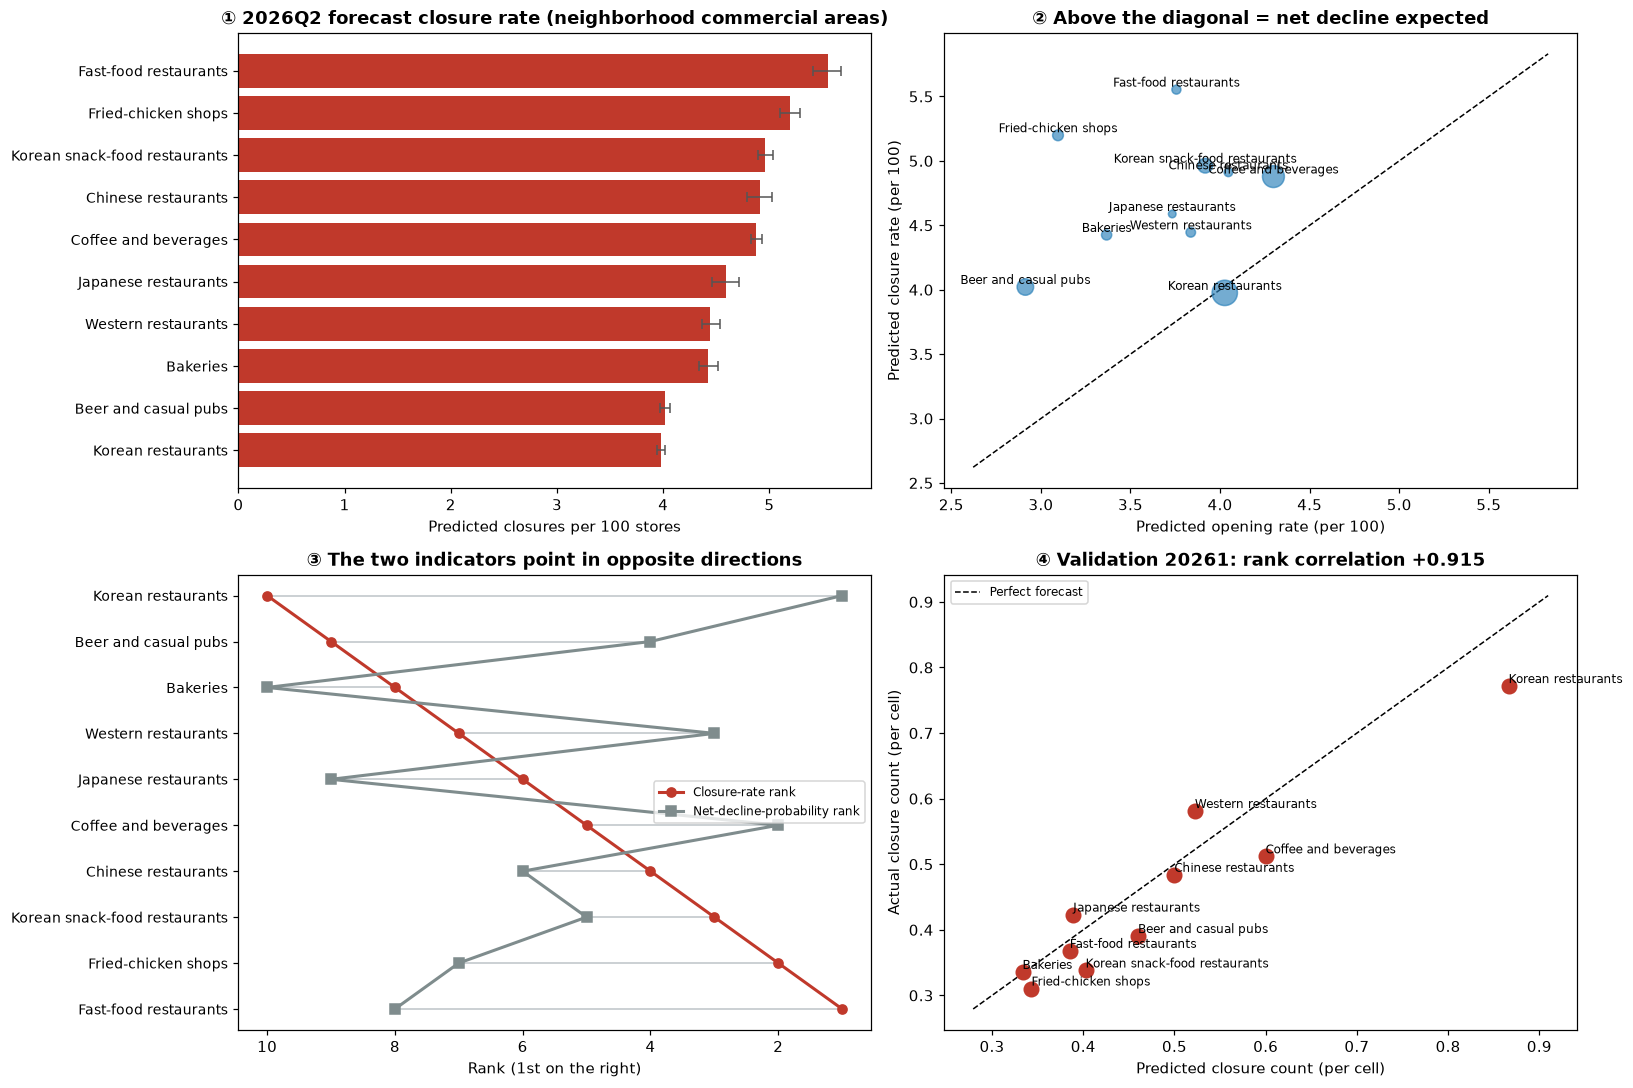

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# ① Closure-rate forecast + confidence interval
c = ci.sort_values("pred_closure_rate")
y = np.arange(len(c))
ax[0,0].barh(y, c["pred_closure_rate"], color="#c0392b",
             xerr=[c["pred_closure_rate"]-c["CI_low"], c["CI_high"]-c["pred_closure_rate"]],
             error_kw=dict(ecolor="#555", lw=1, capsize=3))
ax[0,0].set_yticks(y); ax[0,0].set_yticklabels(c.index, fontsize=9)
ax[0,0].set_xlabel("Predicted closures per 100 stores")
ax[0,0].set_title("① 2026Q2 forecast closure rate (neighborhood commercial areas)", weight="bold")

# ② Opening vs closure
ax[0,1].scatter(pred["pred_opening_rate"], pred["pred_closure_rate"], s=pred["n_cells"]/3,
                c="#2980b9", alpha=.65, zorder=3)
lim = [min(pred[["pred_opening_rate","pred_closure_rate"]].min())*.9,
       max(pred[["pred_opening_rate","pred_closure_rate"]].max())*1.05]
ax[0,1].plot(lim, lim, ls="--", c="k", lw=1)
for i, r in pred.iterrows():
    ax[0,1].annotate(i, (r["pred_opening_rate"], r["pred_closure_rate"]), fontsize=8,
                     ha="center", va="bottom")
ax[0,1].set_xlabel("Predicted opening rate (per 100)"); ax[0,1].set_ylabel("Predicted closure rate (per 100)")
ax[0,1].set_title("② Above the diagonal = net decline expected", weight="bold")

# ③ Rank mismatch between the two indicators
o = pred.sort_values("pred_closure_rate", ascending=False)
yy = np.arange(len(o))
ax[1,0].plot(o["closure_rate_rank"], yy, "o-", c="#c0392b", label="Closure-rate rank", lw=2)
ax[1,0].plot(o["net_decline_rank"], yy, "s-", c="#7f8c8d", label="Net-decline-probability rank", lw=2)
for k in range(len(o)):
    ax[1,0].plot([o["closure_rate_rank"].iloc[k], o["net_decline_rank"].iloc[k]], [k, k],
                 c="#bdc3c7", lw=1, zorder=0)
ax[1,0].set_yticks(yy); ax[1,0].set_yticklabels(o.index, fontsize=9)
ax[1,0].invert_xaxis(); ax[1,0].set_xlabel("Rank (1st on the right)")
ax[1,0].set_title("③ The two indicators point in opposite directions", weight="bold")
ax[1,0].legend(fontsize=8)

# ④ Validation: predicted vs actual
ax[1,1].scatter(chk["pred_closure_count"], chk["actual_closure_count"], s=90, c="#c0392b", zorder=3)
lo = min(chk[["pred_closure_count","actual_closure_count"]].min())*.9
hi = max(chk[["pred_closure_count","actual_closure_count"]].max())*1.05
ax[1,1].plot([lo, hi], [lo, hi], ls="--", c="k", lw=1, label="Perfect forecast")
for i, r in chk.iterrows():
    ax[1,1].annotate(i, (r["pred_closure_count"], r["actual_closure_count"]), fontsize=8,
                     ha="left", va="bottom")
ax[1,1].set_xlabel("Predicted closure count (per cell)"); ax[1,1].set_ylabel("Actual closure count (per cell)")
ax[1,1].set_title(f"④ Validation 20261: rank correlation {r_clos:+.3f}", weight="bold")
ax[1,1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG / "step11_forecast.png", dpi=130)
plt.show()

## 11-6b. Evaluating the closure-count model: comparison with the store-count rule

On the same validation quarter (20254 -> 20261), we check whether the **closure-count model** beats the rule "the more stores a cell has, the more closures it has". The "Closure counts" figures in the README come from this cell.

- **AUC**: the label is whether there was **at least 1 closure** next quarter; the score is the predicted closure count for the model and the store count for the rule.
- **Poisson deviance**: mean deviance against actual closure counts. For the rule, the predicted count is the training-period closure rate x store count, a "store-count-only model".
- **Lift**: the **actual closure incidence (share of cells with at least 1 closure)** in the top (bottom) 10% of cells by score, divided by the incidence over all cells. Store counts have many ties, so for the rule we use the mean and 95% range of 200 repetitions in which the order is shuffled only within ties.

In [11]:
from sklearn.metrics import roc_auc_score, mean_poisson_deviance
from config import rank_order, tie_random_precision

y_cnt  = valid["closure_n"].to_numpy(dtype=float)
y_any  = (y_cnt >= 1).astype(float)                       # whether there is at least 1 closure next quarter
stores = valid["store_count"].to_numpy(dtype=float)
pred_n = valid["pred_closure_count"].to_numpy(dtype=float)
base_n = train["closure_n"].sum() / train["store_count"].sum() * stores   # store-count-only model: training-period closure rate x store count

incid = y_any.mean()                                      # overall closure incidence (at least 1)
K10 = int(round(len(valid) * 0.1))

# Model: top/bottom 10% by predicted closure count (ties fixed in (commercial area, service category, quarter) order)
o_m = rank_order(pred_n, valid)
lift_top_m = y_any[o_m[:K10]].mean() / incid
lift_bot_m = y_any[o_m[-K10:]].mean() / incid

# Rule: top/bottom 10% by store count. Shuffle the order only within ties, repeated 200 times
rng_c = np.random.default_rng(SEED)
top_r = tie_random_precision(stores,  y_any, [K10], rng_c, 200)[:, 0] / incid
bot_r = tie_random_precision(-stores, y_any, [K10], rng_c, 200)[:, 0] / incid

ev = pd.DataFrame([
    {"metric": "validation cells", "store_count_rule": len(valid), "model": len(valid), "description": "20254 features -> 20261 outcome"},
    {"metric": "closure incidence (>=1)", "store_count_rule": incid, "model": incid, "description": "denominator of Lift"},
    {"metric": "AUC (>=1 closure next quarter)", "store_count_rule": roc_auc_score(y_any, stores),
     "model": roc_auc_score(y_any, pred_n), "description": "rule score = store count, model score = predicted closure count"},
    {"metric": "mean Poisson deviance (lower is better)", "store_count_rule": mean_poisson_deviance(y_cnt, base_n),
     "model": mean_poisson_deviance(y_cnt, pred_n), "description": "rule = training-window closure rate x store count"},
    {"metric": "top-10% cells lift", "store_count_rule": top_r.mean(),
     "store_count_rule_ci_low": np.percentile(top_r, 2.5), "store_count_rule_ci_high": np.percentile(top_r, 97.5),
     "model": lift_top_m, "description": "actual closure incidence of the top-10% cells by score / overall incidence (the rule is the mean of 200 random tie-breaks)"},
    {"metric": "bottom-10% cells lift", "store_count_rule": bot_r.mean(),
     "store_count_rule_ci_low": np.percentile(bot_r, 2.5), "store_count_rule_ci_high": np.percentile(bot_r, 97.5),
     "model": lift_bot_m, "description": "actual closure incidence of the bottom-10% cells by score / overall incidence"},
]).set_index("metric")
ev = ev[["store_count_rule", "store_count_rule_ci_low", "store_count_rule_ci_high", "model", "description"]]
display(ev.round(3))
ev.to_csv(OUT / "pred_closure_count_eval.csv", encoding="utf-8-sig")
print("[Saved] outputs/pred_closure_count_eval.csv")
print(f"※ Validation {len(valid):,} cells · closure incidence {incid:.1%} · top/bottom 10% = {K10} cells")

,store_count_rule,store_count_rule_ci_low,store_count_rule_ci_high,model,description
metric,,,,,
validation cells,2772.000,NaN,NaN,2772.000,20254 features -> 20261 outcome
closure incidence (>=1),0.350,NaN,NaN,0.350,denominator of Lift
AUC (>=1 closure next quarter),0.705,NaN,NaN,0.711,"rule score = store count, model score = predic..."
mean Poisson deviance (lower is better),1.002,NaN,NaN,0.992,rule = training-window closure rate x store count
top-10% cells lift,2.183,2.158,2.21,2.251,actual closure incidence of the top-10% cells ...
bottom-10% cells lift,0.544,0.454,0.62,0.444,actual closure incidence of the bottom-10% cel...


[Saved] outputs/pred_closure_count_eval.csv
※ Validation 2,772 cells · closure incidence 35.0% · top/bottom 10% = 277 cells


## 11-7. Save and wrap up

In [12]:
keep = ["quarter_code", "area_code", "district", "area_type",
        "service_code", "service_name", "store_count",
        "p_net_decline", "pred_opening_count", "pred_closure_count", "pred_opening_rate", "pred_closure_rate"]
score[keep].to_pickle(PROC / "11_forecast_2026Q2.pkl")
score[keep].to_csv(OUT / "forecast_2026Q2_cell.csv", index=False, encoding="utf-8-sig")
pred.to_csv(OUT / "forecast_2026Q2_service.csv", encoding="utf-8-sig")
chk.to_csv(OUT / "forecast_validation.csv", encoding="utf-8-sig")
print(f"[Saved] 11_forecast_2026Q2.pkl  {score[keep].shape}  <- cell-level forecast (district aggregation starts from here)")
print("[Saved] outputs/forecast_2026Q2_cell.csv, forecast_2026Q2_service.csv, forecast_validation.csv")
print("[Saved] figures/step11_forecast.png\n")

top_c = pred["pred_closure_rate"].idxmax(); bot_c = pred["pred_closure_rate"].idxmin()
top_n = pred["net_decline_prob"].idxmax()
print("=" * 64)
print(f"2026Q2 forecast: {TARGET_TYPE} food-service {len(score):,} cells")
print("-" * 64)
print(f"  Highest closure rate   {top_c} {pred.loc[top_c,'pred_closure_rate']:.2f}% ({pred.loc[top_c,'pred_closure_rate']:.1f} per 100 stores)")
print(f"  Lowest closure rate   {bot_c} {pred.loc[bot_c,'pred_closure_rate']:.2f}%")
print(f"  Highest net decline   {top_n} {pred.loc[top_n,'net_decline_prob']:.1%}  <- closure-rate rank is {int(pred.loc[top_n,'closure_rate_rank'])}")
print()
print(f"  Validation rank correlation  closure {r_clos:+.3f} / opening {r_open:+.3f} / net decline {r_net:+.3f}")
print()
print("  Interpretation notes")
print("   · 'Net-decline probability' is dragged along by size. Use the closure rate for policy decisions")
print("   · Do not claim a rank difference between service categories whose confidence intervals overlap")
print("   · The district x service category unit cannot be validated (see STEP 8)")
print("=" * 64)

[Saved] 11_forecast_2026Q2.pkl  (2737, 12)  <- cell-level forecast (district aggregation starts from here)
[Saved] outputs/forecast_2026Q2_cell.csv, forecast_2026Q2_service.csv, forecast_validation.csv
[Saved] figures/step11_forecast.png

2026Q2 forecast: neighborhood commercial area food-service 2,737 cells
----------------------------------------------------------------
  Highest closure rate   Fast-food restaurants 5.55% (5.6 per 100 stores)
  Lowest closure rate   Korean restaurants 3.98%
  Highest net decline   Korean restaurants 25.3%  <- closure-rate rank is 10

  Validation rank correlation  closure +0.915 / opening +0.624 / net decline +0.648

  Interpretation notes
   · 'Net-decline probability' is dragged along by size. Use the closure rate for policy decisions
   · Do not claim a rank difference between service categories whose confidence intervals overlap
   · The district x service category unit cannot be validated (see STEP 8)


---

## Where this forecast matches the project conclusion

The conclusion from the H2 validation was **"once size is matched, Korean restaurants are actually safer"**.

This forecast reproduces it independently: **by net-decline probability, Korean restaurants rank 1st (riskiest), but by the closure rate divided by size they rank last (safest).** The causal analysis (STEP 6, 7, 9) and the forecast (STEP 11) reached the same picture by different routes.

In the presentation, putting these two numbers side by side is the most powerful move.

## What remains

- The district x service category aggregation can be built directly from `11_forecast_2026Q2.pkl`. But it must be passed along together with the fact that **that unit cannot be validated on a single quarter** (STEP 8, 8-7)
- Developed commercial areas and traditional markets were not forecast, because the model was trained on neighborhood commercial areas; if needed, it must be retrained by commercial-area type